In [1]:
from sklearn.datasets import fetch_openml
shuttle=fetch_openml(name='shuttle', version=1, as_frame=True)
shuttle.frame.to_csv('shuttle_nasa.csv', index=False)
print(shuttle.DESCR)

Source: [UCI](https://archive.ics.uci.edu/ml/datasets/Statlog+(Shuttle))

Donor:

Jason Catlett
Basser Department of Computer Science,
University of Sydney, N.S.W., Australia



Data Set Information:

Approximately 80% of the data belongs to class 1. Therefore the default accuracy is about 80%. The aim here is to obtain an accuracy of 99 - 99.9%.

The examples in the original dataset were in time order, and this time order could presumably be relevant in classification. However, this was not deemed relevant for StatLog purposes, so the order of the examples in the original dataset was randomised, and a portion of the original dataset removed for validation purposes.


Attribute Information:

The shuttle dataset contains 9 attributes all of which are numerical. The first one being time. The last column is the class which has been coded as follows :
1 Rad Flow
2 Fpv Close
3 Fpv Open
4 High
5 Bypass
6 Bpv Close
7 Bpv Open


Relevant Papers:

N/A

Downloaded from openml.org.


In [2]:
shuttle.details

{'id': '40685',
 'name': 'shuttle',
 'version': '1',
 'description_version': '2',
 'format': 'ARFF',
 'upload_date': '2017-04-06T12:14:35',
 'licence': 'public',
 'url': 'https://openml.org/data/v1/download/4965262/shuttle.arff',
 'parquet_url': 'https://data.openml.org/datasets/0004/40685/dataset_40685.pq',
 'file_id': '4965262',
 'default_target_attribute': 'class',
 'tag': ['Machine Learning', 'study_218', 'study_76', 'Transport'],
 'visibility': 'public',
 'original_data_url': 'https://archive.ics.uci.edu/ml/datasets/Statlog+(Shuttle)',
 'status': 'active',
 'processing_date': '2018-10-04 07:24:35',
 'md5_checksum': '898301c06eebd6e4bbb893bf65d0ae92'}

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import sklearn
import matplotlib.pyplot as plt 
from sklearn.ensemble import IsolationForest 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
plt.style.use('dark_background')


In [12]:
df=pd.read_csv('shuttle_nasa.csv')
df.head(5)

,A1,A2,A3,A4,A5,A6,A7,A8,A9,class
0,50,21,77,0,28,0,27,48,22,2
1,55,0,92,0,0,26,36,92,56,4
2,53,0,82,0,52,-5,29,30,2,1
3,37,0,76,0,28,18,40,48,8,1
4,37,0,79,0,34,-26,43,46,2,1


In [11]:
round(df.describe(),3)

,A1,A2,A3,A4,A5,A6,A7,A8,A9,class
count,58000.000,58000.000,58000.000,58000.000,58000.00,58000.000,58000.000,58000.000,58000.000,58000.000
mean,48.238,-0.019,85.349,0.260,34.55,1.608,37.092,50.885,13.932,1.695
std,12.238,77.958,8.903,36.522,21.66,217.598,13.111,21.418,25.614,1.351
min,27.000,-4821.000,21.000,-3939.000,-188.00,-26739.000,-48.000,-353.000,-356.000,1.000
25%,38.000,0.000,79.000,0.000,26.00,-5.000,32.000,37.000,0.000,1.000
50%,45.000,0.000,83.000,0.000,42.00,0.000,39.000,44.000,2.000,1.000
75%,55.000,0.000,89.000,0.000,46.00,5.000,42.000,60.000,14.000,1.000
max,126.000,5075.000,149.000,3830.000,436.00,15164.000,105.000,270.000,266.000,7.000


In [10]:
sensor_cols=[c for c in df.columns if c != 'class']

In [14]:
df.isnull().sum().sum()

np.int64(0)

In [15]:
print(df['class'].value_counts())

class
1    45586
4     8903
5     3267
3      171
2       50
7       13
6       10
Name: count, dtype: int64


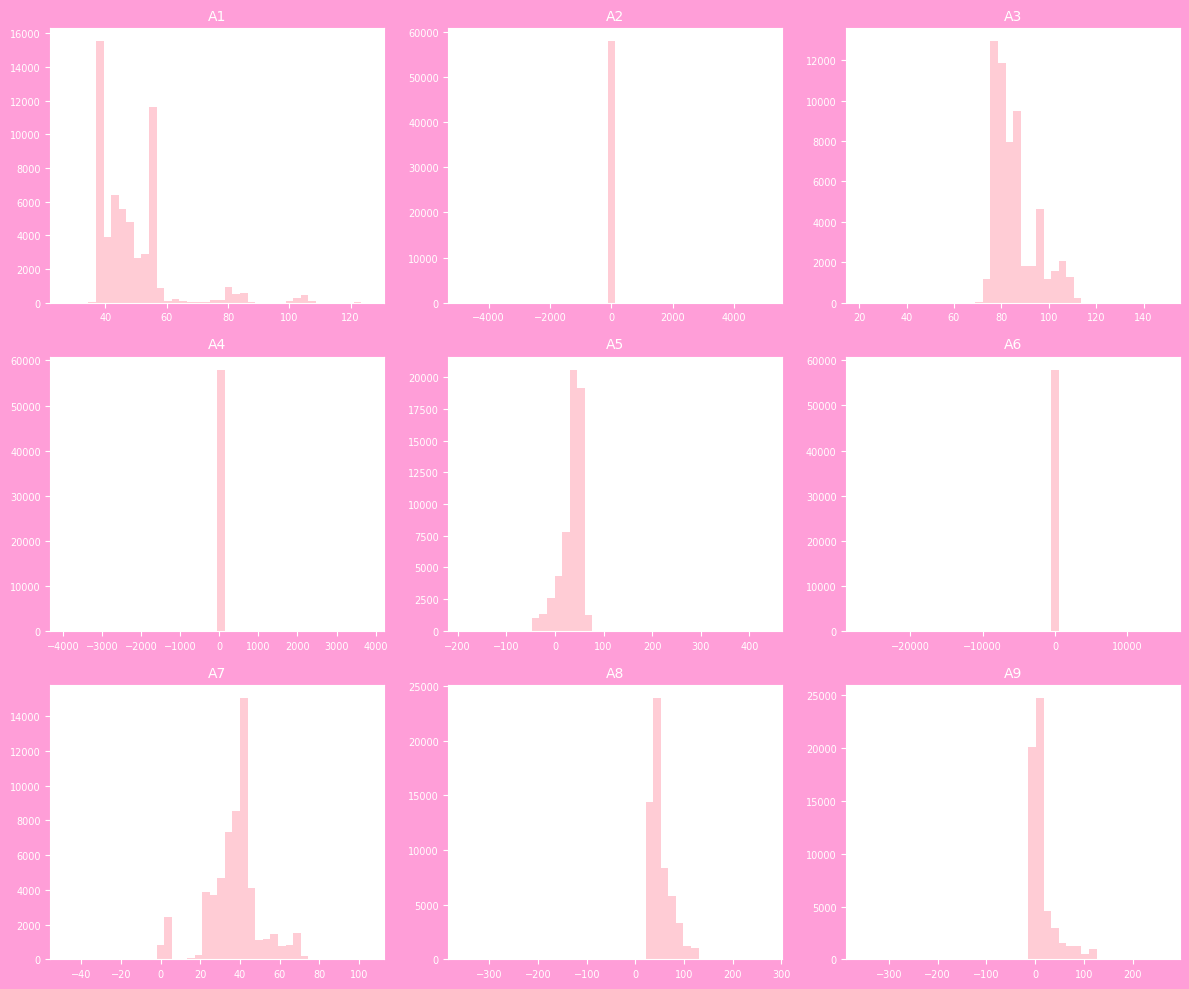

In [24]:
fig, axes=plt.subplots(3, 3, figsize=(12, 10), facecolor="#FF9ED8") 
for ax, col in zip(axes.flatten(), sensor_cols[:9]): 
    ax.hist(df[col], bins=40, color='pink', alpha=0.8) 
    ax.set_title(col, color='white', fontsize=10) 
    ax.set_facecolor('white') 
    ax.tick_params(colors='white', labelsize=7) 
plt.tight_layout() 
plt.show()
plt.close()

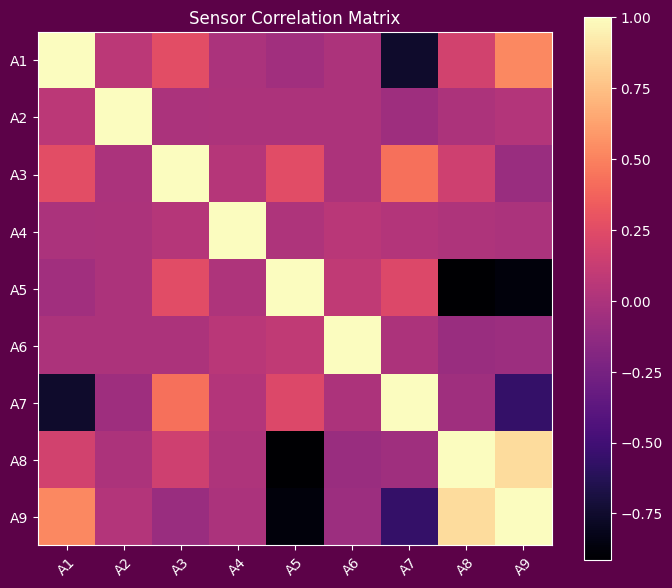

In [29]:
corr=df[sensor_cols].corr()
plt.figure(figsize=(7, 6), facecolor="#5c0248") 
im=plt.imshow(corr, cmap='magma') 
plt.colorbar(im) 
plt.xticks(range(len(sensor_cols)), sensor_cols, rotation=45, color='white') 
plt.yticks(range(len(sensor_cols)), sensor_cols, color='white') 
plt.title('Sensor Correlation Matrix', color='white') 
plt.tight_layout() 
plt.show()
plt.close()

In [33]:
X=df[sensor_cols].values
X_scaled=StandardScaler().fit_transform(X)
model=IsolationForest(contamination=0.03, random_state=42)
preds=model.fit_predict(X_scaled)  # -1 = anomaly, 1 = normal
print(f'Number of anomalies detected: {(preds==-1).sum()}')

Number of anomalies detected: 1740


/Users/mshvrnina/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/mshvrnina/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/mshvrnina/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


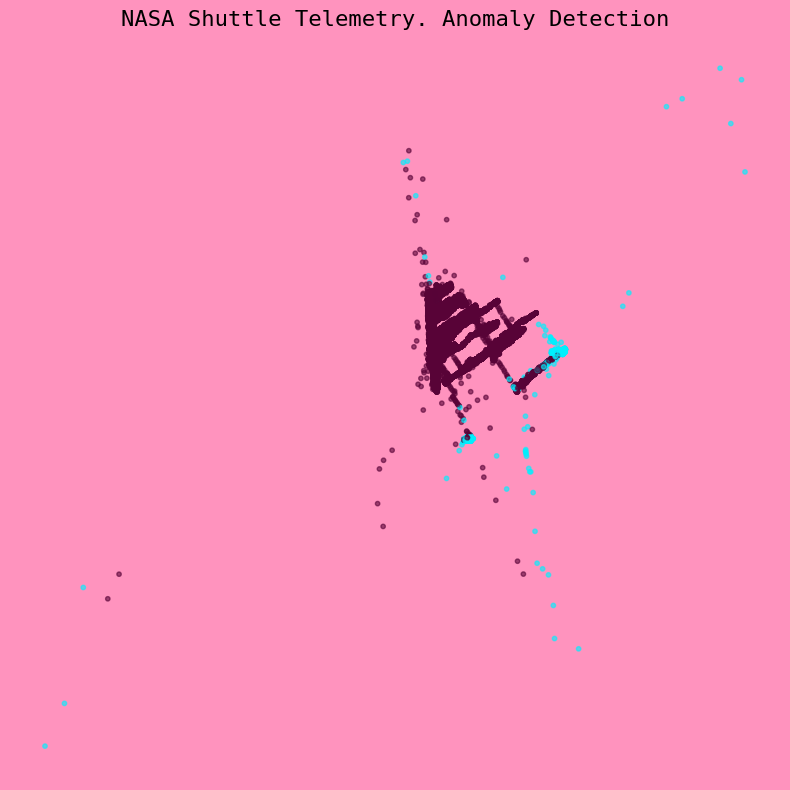


Total readings: 58000
Flagged anomalies: 1740


In [36]:
X_2d=PCA(n_components=2).fit_transform(X_scaled)
colors=np.where(preds == 1, "#580337", '#00f0ff') 
plt.figure(figsize=(8, 8), facecolor="#ff93be")
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=colors, s=10, alpha=0.6)
plt.title("NASA Shuttle Telemetry. Anomaly Detection", fontsize=16, color='black', fontfamily='monospace')
plt.gca().set_facecolor('#0d0221')
plt.axis('off')
plt.tight_layout()
plt.show()
print(f"\nTotal readings: {len(X)}")
print(f"Flagged anomalies: {sum(preds == -1)}")

In [37]:
from sklearn.metrics import ( classification_report, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score )

In [ ]:
y_true=np.where(df['class'] == 1, 1, -1) 
y_pred = preds                       

In [40]:
precision=precision_score(y_true, y_pred, pos_label=-1)
recall=recall_score(y_true, y_pred, pos_label=-1)
f1=f1_score(y_true, y_pred, pos_label=-1)
print(f"Precision: {precision:.3f}") 
print(f"Recall: {recall:.3f}") 
print(f"F1 score: {f1:.3f}")

Precision: 0.997
Recall: 0.140
F1 score: 0.245



Confusion Matrix
Predicted Normal  Predicted Anomaly
Actual Normal               45580                  6
Actual Anomaly              10680               1734


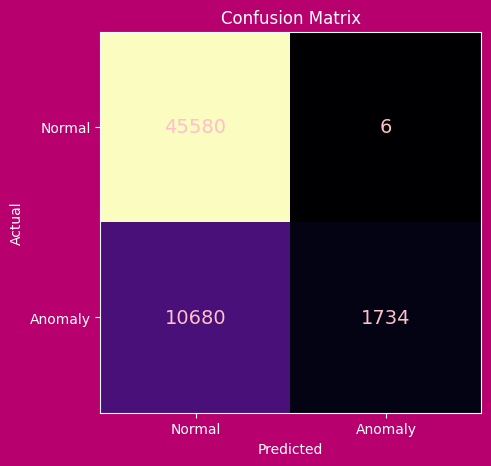

In [43]:
cm=confusion_matrix(y_true, y_pred, labels=[1, -1])
print("\nConfusion Matrix")
print("Predicted Normal  Predicted Anomaly")
print(f"Actual Normal    {cm[0][0]:>16}  {cm[0][1]:>17}") 
print(f"Actual Anomaly   {cm[1][0]:>16}  {cm[1][1]:>17}")
plt.figure(figsize=(5, 5), facecolor="#B7006E") 
plt.imshow(cm, cmap='magma')
plt.xticks([0, 1], ['Normal', 'Anomaly'], color='white')
plt.yticks([0, 1], ['Normal', 'Anomaly'], color='white')
plt.xlabel('Predicted', color='white')
plt.ylabel('Actual', color='white')
plt.title('Confusion Matrix', color='white')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i][j], ha='center', va='center', color='pink', fontsize=14)
plt.tight_layout()
plt.show()
plt.close()

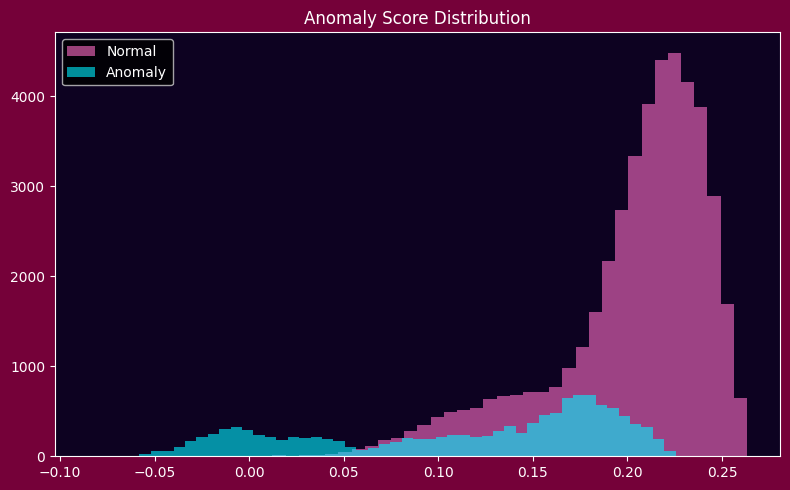

In [44]:
scores=model.decision_function(X_scaled)
plt.figure(figsize=(8, 5), facecolor="#750139") 
plt.hist(scores[y_true == 1], bins=50, alpha=0.6, label='Normal', color='#ff6ec7')
plt.hist(scores[y_true == -1], bins=50, alpha=0.6, label='Anomaly', color='#00f0ff')
plt.legend()
plt.gca().set_facecolor('#0d0221')
plt.title('Anomaly Score Distribution', color='white')
plt.tick_params(colors='white')
plt.tight_layout()
plt.show()